# Práctica 5 — Redes generativas antagónicas sobre MNIST

## Objetivos

Una red generativa antagónica (GAN) aprende a producir ejemplos nuevos mediante dos redes que compiten: el generador crea imágenes y el discriminador intenta distinguirlas de las reales. Esta competencia puede producir imágenes cada vez más parecidas a los datos de entrenamiento, aunque sus pérdidas no siempre disminuyen de forma monótona. En esta práctica se entrena una GAN sencilla sobre MNIST, se visualiza la evolución de sus errores y se evalúa la calidad y diversidad de las muestras con métricas generales y específicas para dígitos.

## 1. Preparación del entorno

In [1]:
import os
import time
from pathlib import Path

BASE_DIR = Path.cwd()
if BASE_DIR.name != 'Practica-5':
    candidatos = (
        BASE_DIR / 'Practica-5',
        BASE_DIR / 'Tema-2-RNN-Convolucionales' / 'Practica-5',
    )
    for candidato in candidatos:
        if candidato.is_dir():
            BASE_DIR = candidato
            break
os.environ['TORCH_HOME'] = str(BASE_DIR / '.torch')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from scipy.linalg import sqrtm
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
N_EVAL = 5_000
CLASSIFIER_EPOCHS = 3
EVAL_BATCH_SIZE = 512

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

torch.manual_seed(SEED)
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')

def sincronizar_dispositivo():
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()

print(f'PyTorch: {torch.__version__} | torchvision: {torchvision.__version__}')
print(f'Dispositivo de entrenamiento: {device}')
print(f'Directorio de trabajo: {BASE_DIR.name}')

PyTorch: 2.14.1 | torchvision: 0.29.1
Dispositivo de entrenamiento: mps
Directorio de trabajo: Practica-5


## 2. Datos y preprocesamiento

Las imágenes se escalan al intervalo $[-1, 1]$, que coincide con la salida `tanh` del generador. El conjunto oficial de prueba se mantiene separado para evaluar el clasificador y construir referencias de las métricas. La semilla del generador del `DataLoader` hace reproducible el orden de los lotes.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

data_root = BASE_DIR / '.torch' / 'data'
mnist_train = datasets.MNIST(
    root=data_root, train=True, download=True, transform=transform)
mnist_test = datasets.MNIST(
    root=data_root, train=False, download=True, transform=transform)
loader_generator = torch.Generator().manual_seed(SEED)
dataloader = DataLoader(
    mnist_train, batch_size=BATCH_SIZE, shuffle=True, generator=loader_generator)
test_dataloader = DataLoader(
    mnist_test, batch_size=EVAL_BATCH_SIZE, shuffle=False)

print(f'Imágenes de entrenamiento: {len(mnist_train):,}')
print(f'Imágenes de prueba: {len(mnist_test):,}')
print(f'Tamaño de lote para la GAN: {BATCH_SIZE}')

Imágenes de entrenamiento: 60,000
Imágenes de prueba: 10,000
Tamaño de lote para la GAN: 128


## 3. Modelos generativo y discriminador

El generador transforma un vector latente aleatorio en los 784 píxeles de un dígito. El discriminador recibe una imagen aplanada y estima la probabilidad de que proceda del conjunto real. Se conserva exactamente la arquitectura de la plantilla.

### Generador

In [3]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_dim=28*28):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.ReLU(True),
            nn.Linear(256, 512),
            nn.ReLU(True),
            nn.Linear(512, img_dim),
            nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)

### Discriminador

In [4]:
class Discriminator(nn.Module):
    def __init__(self, img_dim=28*28):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

z_dim = 100
generator = Generator(z_dim).to(device)
discriminator = Discriminator().to(device)

parametros_generador = sum(p.numel() for p in generator.parameters())
parametros_discriminador = sum(p.numel() for p in discriminator.parameters())
print(f'Parámetros del generador: {parametros_generador:,}')
print(f'Parámetros del discriminador: {parametros_discriminador:,}')

Parámetros del generador: 559,632
Parámetros del discriminador: 533,505


## 4. Clasificador evaluador para MNIST

Se entrena una CNN pequeña sobre las imágenes reales. Además de medir su exactitud, se usan sus activaciones de 128 dimensiones como representación propia del dominio de dígitos: con ellas se calcula una distancia de Fréchet específica para MNIST, y sus probabilidades permiten estimar diversidad y confianza.

In [5]:
class EvaluadorMNIST(nn.Module):
    def __init__(self):
        super().__init__()
        self.convoluciones = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25),
            nn.Flatten()
        )
        self.fc1 = nn.Linear(9216, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def features(self, x):
        return torch.relu(self.fc1(self.convoluciones(x)))

    def probs(self, x):
        return torch.softmax(self(x), dim=1)

    def forward(self, x):
        return self.fc2(self.dropout(self.features(x)))


def stats(features):
    features = np.asarray(features, dtype=np.float64)
    return features.mean(axis=0), np.cov(features, rowvar=False)


def frechet_distance(mu1, s1, mu2, s2):
    diff = mu1 - mu2
    # Una regularización mínima estabiliza la raíz cuando una covarianza es singular.
    regularizador = 1e-6 * np.eye(s1.shape[0], dtype=np.float64)
    covmean = sqrtm((s1 + regularizador) @ (s2 + regularizador)).real
    return float(diff @ diff + np.trace(s1 + s2 - 2 * covmean))


def classifier_is(probs, splits=10):
    if not 1 <= splits <= 10:
        raise ValueError('El número de particiones debe estar entre 1 y 10.')
    probs = np.asarray(probs, dtype=np.float64)
    puntuaciones = []
    for parte in np.array_split(probs, splits):
        marginal = parte.mean(axis=0, keepdims=True)
        kl = np.sum(
            parte * (
                np.log(np.clip(parte, 1e-16, 1.0))
                - np.log(np.clip(marginal, 1e-16, 1.0))
            ),
            axis=1,
        )
        puntuaciones.append(np.exp(kl.mean()))
    return float(np.mean(puntuaciones)), float(np.std(puntuaciones))


evaluator = EvaluadorMNIST().to(device)
optimizer_evaluator = optim.Adam(evaluator.parameters(), lr=1e-3)
criterion_evaluator = nn.CrossEntropyLoss()
inicio_clasificador = time.perf_counter()

for epoch in range(CLASSIFIER_EPOCHS):
    evaluator.train()
    perdidas_clasificador = []
    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer_evaluator.zero_grad()
        logits = evaluator(images)
        loss = criterion_evaluator(logits, labels)
        loss.backward()
        optimizer_evaluator.step()
        perdidas_clasificador.append(loss.item())
    print(
        f'Época {epoch + 1}/{CLASSIFIER_EPOCHS} del clasificador | '
        f'error medio: {np.mean(perdidas_clasificador):.4f}'
    )

evaluator.eval()
aciertos = 0
etiquetas_test = []
probabilidades_test = []
confianzas_test = []
caracteristicas_test = []
with torch.inference_mode():
    for images, labels in test_dataloader:
        images = images.to(device)
        caracteristicas = evaluator.features(images)
        probabilidades = evaluator.probs(images)
        predicciones = probabilidades.argmax(dim=1)
        aciertos += (predicciones.cpu() == labels).sum().item()
        etiquetas_test.append(labels.numpy())
        probabilidades_test.append(probabilidades.cpu().numpy())
        confianzas_test.append(probabilidades.max(dim=1).values.cpu().numpy())
        caracteristicas_test.append(caracteristicas.cpu().numpy())

etiquetas_test = np.concatenate(etiquetas_test)
probabilidades_test = np.concatenate(probabilidades_test)
confianzas_test = np.concatenate(confianzas_test)
caracteristicas_test = np.concatenate(caracteristicas_test)
exactitud_test = aciertos / len(mnist_test)
print(f'Exactitud de prueba del clasificador: {exactitud_test:.4%}')

indices_test_metricas = torch.randperm(
    len(mnist_test), generator=torch.Generator().manual_seed(SEED + 6)
)[:N_EVAL].numpy()
etiquetas_test = etiquetas_test[indices_test_metricas]
probabilidades_test = probabilidades_test[indices_test_metricas]
confianzas_test = confianzas_test[indices_test_metricas]
caracteristicas_test = caracteristicas_test[indices_test_metricas]

caracteristicas_train = []
referencia_train_loader = DataLoader(
    mnist_train, batch_size=EVAL_BATCH_SIZE, shuffle=False)
with torch.inference_mode():
    for images, _ in referencia_train_loader:
        caracteristicas_train.append(
            evaluator.features(images.to(device)).cpu().numpy())
caracteristicas_train = np.concatenate(caracteristicas_train)
mu_train, cov_train = stats(caracteristicas_train)
mu_test, cov_test = stats(caracteristicas_test)
fid_mnist_referencia = frechet_distance(mu_train, cov_train, mu_test, cov_test)

print(f'Características de referencia calculadas: {len(caracteristicas_train):,}')
print(f'FID-MNIST de referencia (test frente a entrenamiento): {fid_mnist_referencia:.4f}')
print(f'Tiempo de entrenamiento y referencias del clasificador: '
      f'{time.perf_counter() - inicio_clasificador:.1f} s')

Época 1/3 del clasificador | error medio: 0.2629


Época 2/3 del clasificador | error medio: 0.0897


Época 3/3 del clasificador | error medio: 0.0675


Exactitud de prueba del clasificador: 98.8300%


Características de referencia calculadas: 60,000
FID-MNIST de referencia (test frente a entrenamiento): 3.2296
Tiempo de entrenamiento y referencias del clasificador: 25.8 s


## 5. Entrenamiento de la GAN

Se mantienen los hiperparámetros y el orden de actualización de la plantilla: primero se optimiza el discriminador con imágenes reales y generadas y después se actualiza el generador con la pérdida no saturante. Se guarda un registro por iteración y se evalúa el generador al final de cada época con el mismo ruido fijo. El FID-MNIST compara las características de esas muestras con las del conjunto real de entrenamiento.

In [6]:
lr = 0.0002
criterion = nn.BCELoss()
optimizer_gen = optim.Adam(generator.parameters(), lr=lr)
optimizer_disc = optim.Adam(discriminator.parameters(), lr=lr)
num_epochs = 50

fixed_noise = torch.randn(
    64, z_dim, generator=torch.Generator().manual_seed(SEED + 1))
fixed_eval_noise = torch.randn(
    N_EVAL, z_dim, generator=torch.Generator().manual_seed(SEED + 2))
epocas_progresion = (1, 5, 10, 25, 50)
progresion_muestras = {}

loss_disc_history = []
loss_gen_history = []
d_real_history = []
d_fake_history = []
epoch_history = []
inicio_entrenamiento = time.perf_counter()

for epoch in range(num_epochs):
    inicio_epoca = time.perf_counter()
    generator.train()
    discriminator.train()
    perdidas_disc_epoca = []
    perdidas_gen_epoca = []
    d_real_epoca = []
    d_fake_epoca = []

    for real, _ in dataloader:
        real = real.view(-1, 28 * 28).to(device)
        batch_size = real.size(0)
        label_real = torch.ones(batch_size, 1, device=device)
        label_fake = torch.zeros(batch_size, 1, device=device)

        noise = torch.randn(batch_size, z_dim, device=device)
        fake = generator(noise)
        output_real = discriminator(real)
        output_fake = discriminator(fake.detach())
        loss_disc_real = criterion(output_real, label_real)
        loss_disc_fake = criterion(output_fake, label_fake)
        loss_disc = (loss_disc_real + loss_disc_fake) / 2

        optimizer_disc.zero_grad()
        loss_disc.backward()
        optimizer_disc.step()

        output = discriminator(fake)
        loss_gen = criterion(output, label_real)
        optimizer_gen.zero_grad()
        loss_gen.backward()
        optimizer_gen.step()

        valores_iteracion = (
            loss_disc.item(),
            loss_gen.item(),
            output_real.mean().item(),
            output_fake.mean().item(),
        )
        perdidas_disc_epoca.append(valores_iteracion[0])
        perdidas_gen_epoca.append(valores_iteracion[1])
        d_real_epoca.append(valores_iteracion[2])
        d_fake_epoca.append(valores_iteracion[3])
        loss_disc_history.append(valores_iteracion[0])
        loss_gen_history.append(valores_iteracion[1])
        d_real_history.append(valores_iteracion[2])
        d_fake_history.append(valores_iteracion[3])

    sincronizar_dispositivo()
    generator.eval()
    caracteristicas_generadas = []
    with torch.inference_mode():
        for inicio in range(0, N_EVAL, EVAL_BATCH_SIZE):
            ruido = fixed_eval_noise[inicio:inicio + EVAL_BATCH_SIZE].to(device)
            muestras = generator(ruido).view(-1, 1, 28, 28)
            caracteristicas_generadas.append(
                evaluator.features(muestras).cpu().numpy())
        if epoch + 1 in epocas_progresion:
            progresion_muestras[epoch + 1] = generator(
                fixed_noise.to(device)
            ).view(-1, 1, 28, 28).cpu()

    mu_generado, cov_generado = stats(np.concatenate(caracteristicas_generadas))
    fid_mnist_epoca = frechet_distance(mu_train, cov_train, mu_generado, cov_generado)
    generator.train()
    sincronizar_dispositivo()
    tiempo_epoca = time.perf_counter() - inicio_epoca

    registro_epoca = {
        'epoca': epoch + 1,
        'perdida_disc_media': float(np.mean(perdidas_disc_epoca)),
        'perdida_disc_desviacion': float(np.std(perdidas_disc_epoca)),
        'perdida_gen_media': float(np.mean(perdidas_gen_epoca)),
        'perdida_gen_desviacion': float(np.std(perdidas_gen_epoca)),
        'prob_real_media': float(np.mean(d_real_epoca)),
        'prob_real_desviacion': float(np.std(d_real_epoca)),
        'prob_generada_media': float(np.mean(d_fake_epoca)),
        'prob_generada_desviacion': float(np.std(d_fake_epoca)),
        'fid_mnist': fid_mnist_epoca,
        'tiempo_epoca_s': tiempo_epoca,
    }
    epoch_history.append(registro_epoca)
    print(
        f'Época {epoch + 1:02d}/{num_epochs} | '
        f'Error_D: {registro_epoca["perdida_disc_media"]:.4f} | '
        f'Error_G: {registro_epoca["perdida_gen_media"]:.4f} | '
        f'D(x): {registro_epoca["prob_real_media"]:.4f} | '
        f'D(G(z)): {registro_epoca["prob_generada_media"]:.4f} | '
        f'FID-MNIST: {fid_mnist_epoca:.4f} | '
        f'tiempo: {tiempo_epoca:.1f} s'
    )

sincronizar_dispositivo()
tiempo_entrenamiento = time.perf_counter() - inicio_entrenamiento
historial = pd.DataFrame(epoch_history)
ruta_generador = BASE_DIR / 'generador_gan_mnist.pt'
torch.save(
    {nombre: tensor.detach().cpu() for nombre, tensor in generator.state_dict().items()},
    ruta_generador,
)
ruta_historial = BASE_DIR / 'historial_entrenamiento.csv'
historial.to_csv(ruta_historial, index=False)

print(f'Tiempo total de entrenamiento: {tiempo_entrenamiento:.1f} s')
print(f'Generador guardado en: {ruta_generador.name}')
print(f'Historial guardado en: {ruta_historial.name}')

Época 01/50 | Error_D: 0.1347 | Error_G: 4.3998 | D(x): 0.9389 | D(G(z)): 0.1434 | FID-MNIST: 1514.1823 | tiempo: 4.2 s


Época 02/50 | Error_D: 0.1180 | Error_G: 5.3661 | D(x): 0.9369 | D(G(z)): 0.0917 | FID-MNIST: 1614.3433 | tiempo: 4.1 s


Época 03/50 | Error_D: 0.2400 | Error_G: 4.3496 | D(x): 0.8737 | D(G(z)): 0.1532 | FID-MNIST: 1591.0730 | tiempo: 4.1 s


Época 04/50 | Error_D: 0.2688 | Error_G: 3.6376 | D(x): 0.8594 | D(G(z)): 0.1687 | FID-MNIST: 1602.7230 | tiempo: 4.0 s


Época 05/50 | Error_D: 0.3894 | Error_G: 2.6619 | D(x): 0.7875 | D(G(z)): 0.2368 | FID-MNIST: 1572.0955 | tiempo: 4.1 s


Época 06/50 | Error_D: 0.1188 | Error_G: 3.4206 | D(x): 0.9189 | D(G(z)): 0.0894 | FID-MNIST: 1622.6745 | tiempo: 4.1 s


... (40 outputs left out)

Época 47/50 | Error_D: 0.2554 | Error_G: 3.0725 | D(x): 0.8485 | D(G(z)): 0.1554 | FID-MNIST: 636.3413 | tiempo: 4.1 s


Época 48/50 | Error_D: 0.2731 | Error_G: 2.8241 | D(x): 0.8374 | D(G(z)): 0.1675 | FID-MNIST: 597.2397 | tiempo: 4.1 s


Época 49/50 | Error_D: 0.2668 | Error_G: 3.0077 | D(x): 0.8415 | D(G(z)): 0.1633 | FID-MNIST: 627.2085 | tiempo: 4.0 s


Época 50/50 | Error_D: 0.2556 | Error_G: 3.1561 | D(x): 0.8492 | D(G(z)): 0.1560 | FID-MNIST: 657.4302 | tiempo: 4.1 s
Tiempo total de entrenamiento: 204.2 s
Generador guardado en: generador_gan_mnist.pt
Historial guardado en: historial_entrenamiento.csv


## 6. Evolución de los errores

En una GAN las dos redes juegan un problema minimax: la pérdida de una depende de lo que aprenda la otra, por lo que no se espera una disminución monótona. La línea de referencia $\ln 2$ corresponde a las dos pérdidas cuando el discriminador no distingue las muestras y devuelve 0,5; por sí sola, acercarse a esa línea no garantiza que los dígitos generados sean convincentes. Por eso se muestran también las salidas del discriminador y el FID-MNIST.

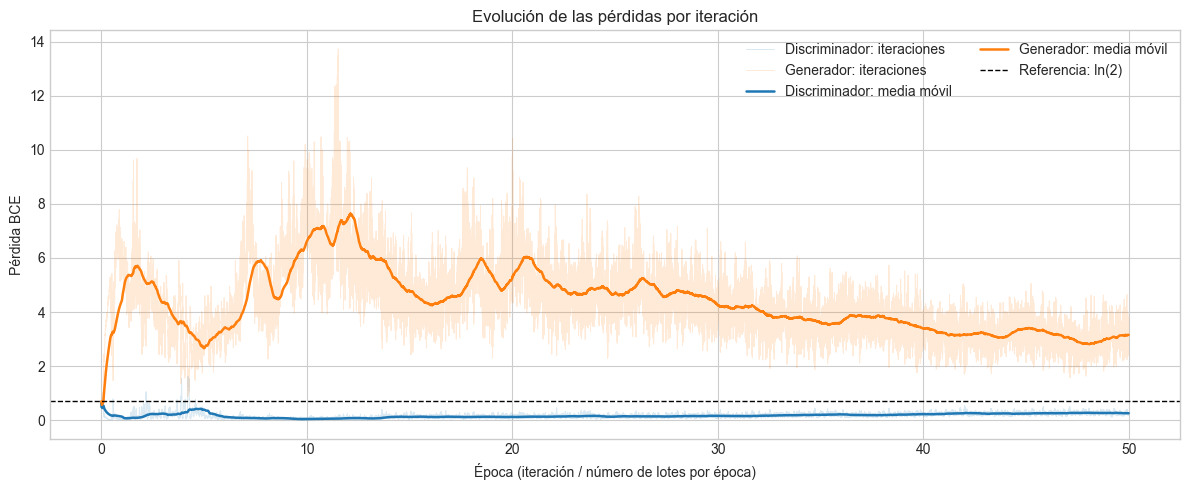

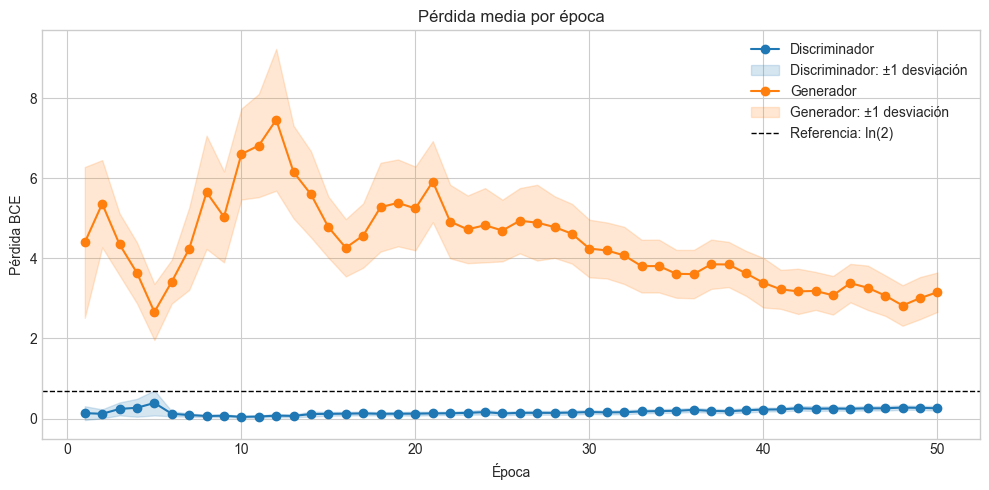

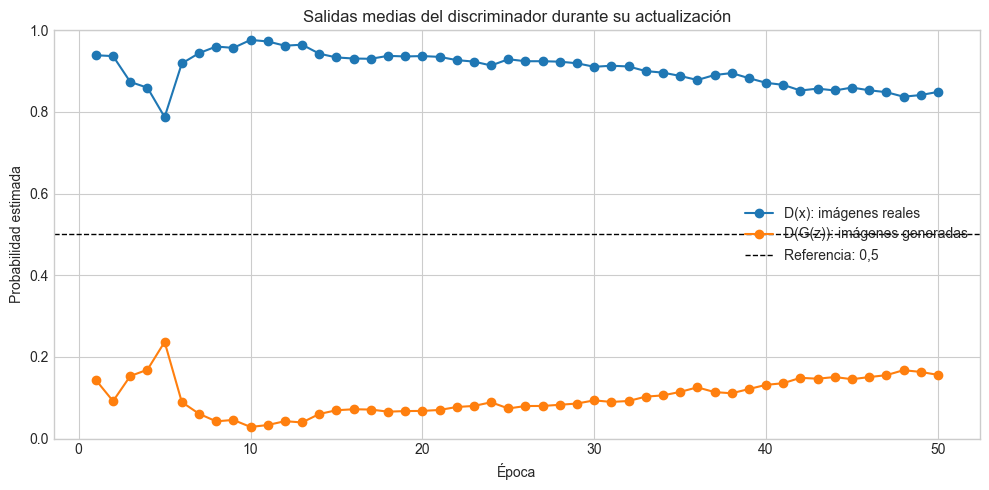

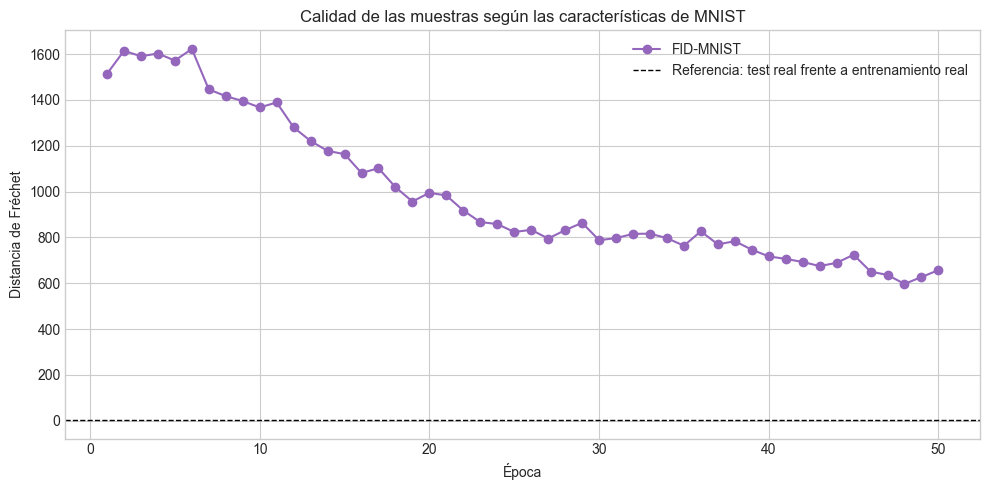

In [7]:
iteraciones = np.arange(1, len(loss_disc_history) + 1)
epocas_x = iteraciones / len(dataloader)
ventana = len(dataloader)
media_movil_disc = pd.Series(loss_disc_history).rolling(
    ventana, min_periods=1).mean().to_numpy()
media_movil_gen = pd.Series(loss_gen_history).rolling(
    ventana, min_periods=1).mean().to_numpy()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(epocas_x, loss_disc_history, color='tab:blue', alpha=0.16, linewidth=0.7,
        label='Discriminador: iteraciones')
ax.plot(epocas_x, loss_gen_history, color='tab:orange', alpha=0.16, linewidth=0.7,
        label='Generador: iteraciones')
ax.plot(epocas_x, media_movil_disc, color='tab:blue', linewidth=1.8,
        label='Discriminador: media móvil')
ax.plot(epocas_x, media_movil_gen, color='tab:orange', linewidth=1.8,
        label='Generador: media móvil')
ax.axhline(np.log(2), color='black', linestyle='--', linewidth=1,
           label='Referencia: ln(2)')
ax.set_title('Evolución de las pérdidas por iteración')
ax.set_xlabel('Época (iteración / número de lotes por época)')
ax.set_ylabel('Pérdida BCE')
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

epocas = historial['epoca'].to_numpy()
fig, ax = plt.subplots(figsize=(10, 5))
for columna, etiqueta, color in (
    ('perdida_disc', 'Discriminador', 'tab:blue'),
    ('perdida_gen', 'Generador', 'tab:orange'),
):
    media = historial[f'{columna}_media'].to_numpy()
    desviacion = historial[f'{columna}_desviacion'].to_numpy()
    ax.plot(epocas, media, marker='o', color=color, label=etiqueta)
    ax.fill_between(epocas, media - desviacion, media + desviacion,
                    color=color, alpha=0.18, label=f'{etiqueta}: ±1 desviación')
ax.axhline(np.log(2), color='black', linestyle='--', linewidth=1,
           label='Referencia: ln(2)')
ax.set_title('Pérdida media por época')
ax.set_xlabel('Época')
ax.set_ylabel('Pérdida BCE')
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(epocas, historial['prob_real_media'], marker='o', label='D(x): imágenes reales')
ax.plot(epocas, historial['prob_generada_media'], marker='o',
        label='D(G(z)): imágenes generadas')
ax.axhline(0.5, color='black', linestyle='--', linewidth=1,
           label='Referencia: 0,5')
ax.set_title('Salidas medias del discriminador durante su actualización')
ax.set_xlabel('Época')
ax.set_ylabel('Probabilidad estimada')
ax.set_ylim(0, 1)
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(epocas, historial['fid_mnist'], marker='o', color='tab:purple',
        label='FID-MNIST')
ax.axhline(fid_mnist_referencia, color='black', linestyle='--', linewidth=1,
           label='Referencia: test real frente a entrenamiento real')
ax.set_title('Calidad de las muestras según las características de MNIST')
ax.set_xlabel('Época')
ax.set_ylabel('Distancia de Fréchet')
ax.legend()
fig.tight_layout()
plt.show()

## 7. Muestreo

La primera figura conserva la visualización de la plantilla: dieciséis imágenes en una fila. Después se muestran una cuadrícula de 64 muestras finales y la evolución de las mismas entradas latentes en las épocas seleccionadas.

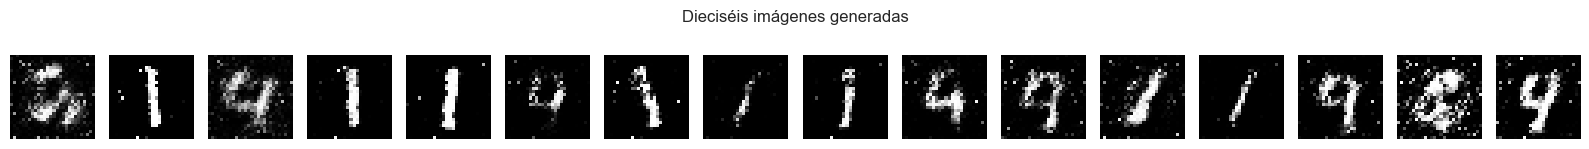

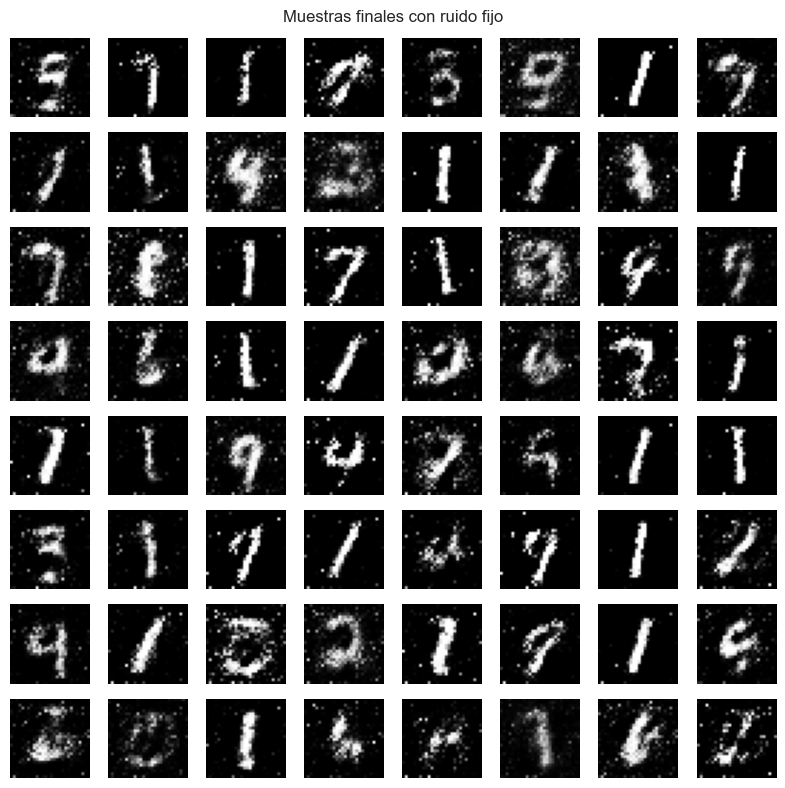

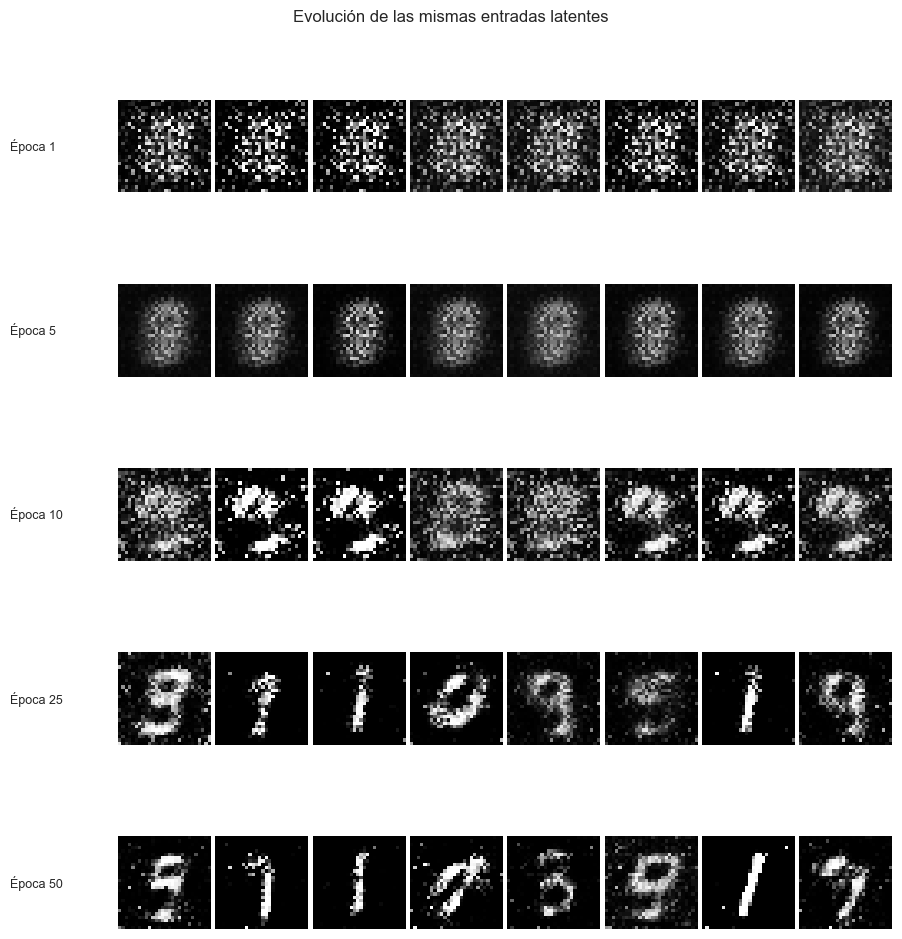

In [8]:
n_images = 16
generator.eval()
with torch.inference_mode():
    noise = torch.randn(
        n_images, z_dim, generator=torch.Generator().manual_seed(SEED + 3)
    ).to(device)
    gen_imgs = generator(noise).cpu().numpy().reshape(n_images, 28, 28)

fig, axes = plt.subplots(1, n_images, figsize=(n_images, 1.5))
for img, ax in zip(gen_imgs, axes):
    ax.imshow((img + 1) / 2, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
fig.suptitle('Dieciséis imágenes generadas')
fig.tight_layout()
plt.show()

imagenes_fijas = progresion_muestras[num_epochs].numpy().reshape(64, 28, 28)
fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for img, ax in zip(imagenes_fijas, axes.flat):
    ax.imshow((img + 1) / 2, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
fig.suptitle('Muestras finales con ruido fijo')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(
    len(epocas_progresion), 8, figsize=(9, 2.0 * len(epocas_progresion)))
for fila, epoca in enumerate(epocas_progresion):
    imagenes = progresion_muestras[epoca].numpy().reshape(64, 28, 28)
    for columna, ax in enumerate(axes[fila]):
        ax.imshow((imagenes[columna] + 1) / 2, cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
fig.suptitle('Evolución de las mismas entradas latentes')
fig.subplots_adjust(left=0.13, right=0.99, top=0.92, bottom=0.03,
                    hspace=0.2, wspace=0.05)
for fila, epoca in enumerate(epocas_progresion):
    posicion = axes[fila, 0].get_position()
    fig.text(0.01, posicion.y0 + posicion.height / 2,
             f'Época {epoca}', ha='left', va='center', fontsize=9)
plt.show()

## 8. Métricas del modelo

### 8.1. Inception Score y Fréchet Inception Distance

Se usa `torchmetrics` con el extractor Inception de `torch-fidelity`. `torcheval` aparece como alternativa en la plantilla, pero no se usa porque dejó de mantenerse en 2023. Las métricas ImageNet se interpretan solo de forma relativa en MNIST: el extractor fue entrenado con fotografías a color, no con dígitos grises pequeños. Para reducir el tiempo de cómputo, se calcula el IS de las muestras generadas y el FID frente a una muestra real de entrenamiento; no se calculan el IS de prueba ni el FID real frente a real.

In [9]:
%pip install -q torchmetrics==1.9.0 torch-fidelity==0.4.0


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: /Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-1-Intro-RNN/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [10]:
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.inception import InceptionScore

# Los estados se acumulan en float64 en CPU, ya que MPS no admite ese tipo;
# solo la red Inception se ejecuta en el acelerador disponible.
metrics_device = (
    torch.device('cuda') if torch.cuda.is_available()
    else torch.device('mps') if torch.backends.mps.is_available()
    else torch.device('cpu')
)

class ExtractorEnDispositivo(nn.Module):
    def __init__(self, modelo, dispositivo):
        super().__init__()
        self.modelo, self.dispositivo = modelo.to(dispositivo), dispositivo

    def forward(self, x):
        return self.modelo(x.to(self.dispositivo)).cpu()

def imagenes_para_metricas(images):
    images = ((images + 1) / 2 * 255).round().clamp(0, 255).to(torch.uint8)
    return images.reshape(-1, 1, 28, 28).repeat(1, 3, 1, 1)

def sincronizar_metricas():
    if metrics_device.type == 'cuda':
        torch.cuda.synchronize()

ruido_metricas = torch.randn(
    N_EVAL, z_dim, generator=torch.Generator().manual_seed(SEED + 4))
inicio_metricas = time.perf_counter()
imagenes_generadas_metricas = torch.empty(N_EVAL, 1, 28, 28)
generator.eval()
with torch.inference_mode():
    for inicio in range(0, N_EVAL, EVAL_BATCH_SIZE):
        fin = min(inicio + EVAL_BATCH_SIZE, N_EVAL)
        ruido = ruido_metricas[inicio:fin].to(device)
        imagenes_generadas_metricas[inicio:fin] = generator(ruido).view(-1, 1, 28, 28).cpu()

indices_train_metricas = torch.randperm(
    len(mnist_train), generator=torch.Generator().manual_seed(SEED + 5)
)[:N_EVAL].tolist()
train_metricas_loader = DataLoader(
    Subset(mnist_train, indices_train_metricas), batch_size=250, shuffle=False)

is_metric = InceptionScore(normalize=False)
is_metric.inception = ExtractorEnDispositivo(is_metric.inception, metrics_device)
sincronizar_metricas()
inicio = time.perf_counter()
for inicio_lote in range(0, N_EVAL, 250):
    lote = imagenes_para_metricas(
        imagenes_generadas_metricas[inicio_lote:inicio_lote + 250]
    )
    is_metric.update(lote)
is_generado, is_generado_std = is_metric.compute()
sincronizar_metricas()
tiempo_is_generado = time.perf_counter() - inicio

fid_metric = FrechetInceptionDistance(
    feature=2048, reset_real_features=False)
fid_metric.inception = ExtractorEnDispositivo(fid_metric.inception, metrics_device)
sincronizar_metricas()
inicio = time.perf_counter()
for images, _ in train_metricas_loader:
    fid_metric.update(imagenes_para_metricas(images), real=True)
sincronizar_metricas()
tiempo_fid_real = time.perf_counter() - inicio

sincronizar_metricas()
inicio = time.perf_counter()
for inicio_lote in range(0, N_EVAL, 250):
    lote = imagenes_para_metricas(
        imagenes_generadas_metricas[inicio_lote:inicio_lote + 250]
    )
    fid_metric.update(lote, real=False)
fid_generado = fid_metric.compute()
sincronizar_metricas()
tiempo_fid_generado = time.perf_counter() - inicio

print(f'Dispositivo de las métricas ImageNet: {metrics_device}')
print(f'IS generado: {is_generado.item():.4f} ± {is_generado_std.item():.4f}')
print(f'FID generado frente a entrenamiento real: {fid_generado.item():.4f}')
print(f'Tiempo IS generado: {tiempo_is_generado:.1f} s')
print(f'Tiempo acumulación FID real: {tiempo_fid_real:.1f} s')
print(f'Tiempo FID generado: {tiempo_fid_generado:.1f} s')

/Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-1-Intro-RNN/.venv/lib/python3.13/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


Dispositivo de las métricas ImageNet: mps
IS generado: 2.0014 ± 0.0317
FID generado frente a entrenamiento real: 183.0416
Tiempo IS generado: 40.9 s
Tiempo acumulación FID real: 50.2 s
Tiempo FID generado: 69.8 s


### 8.2. Métricas del dominio de dígitos

El clasificador evaluador complementa las métricas ImageNet con características y probabilidades aprendidas directamente de MNIST. La distribución de clases permite detectar colapso de modos; la entropía normalizada se acerca a uno cuando las diez clases aparecen de forma equilibrada. La confianza máxima se compara con la de las imágenes reales de prueba.

IS del clasificador — generado: 4.0692 ± 0.1024; test real: 9.5997 ± 0.0541
FID-MNIST — generado frente a entrenamiento real: 655.4525; referencia test real: 3.2296
Proporción de clases generadas: [0.0196 0.4076 0.0758 0.1054 0.089  0.0366 0.047  0.1294 0.0218 0.0678]
Proporción de clase máxima/mínima: 40.7600% / 1.9600%
Entropía normalizada de clases — generado: 0.8191; real: 0.9993
Confianza máxima — generado: {'media': 0.8254724740982056, 'desviacion': 0.21934813261032104, 'mediana': 0.950137734413147, 'percentil_90': 0.9999492168426514, 'porcentaje_mayor_0_9': 56.86}
Confianza máxima — test real: {'media': 0.9892509579658508, 'desviacion': 0.0557224340736866, 'mediana': 0.9999766945838928, 'percentil_90': 0.9999998807907104, 'porcentaje_mayor_0_9': 97.1}


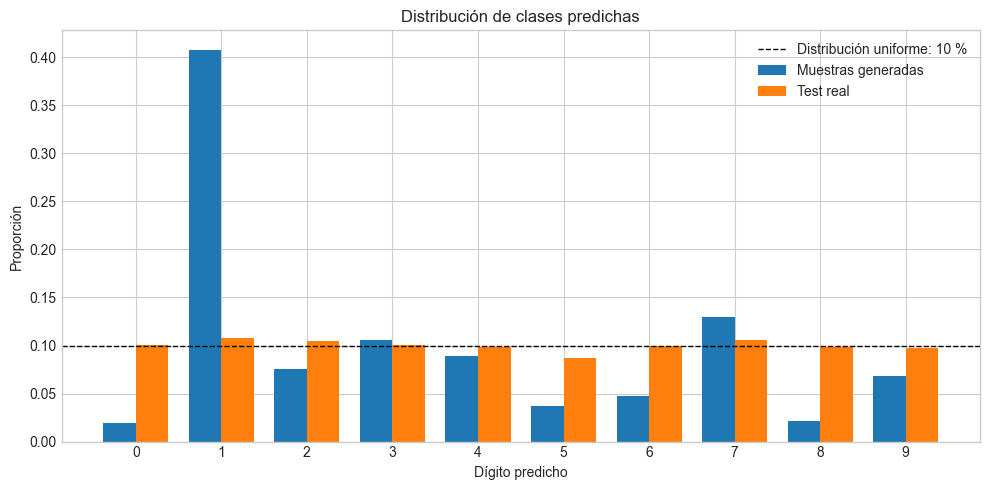

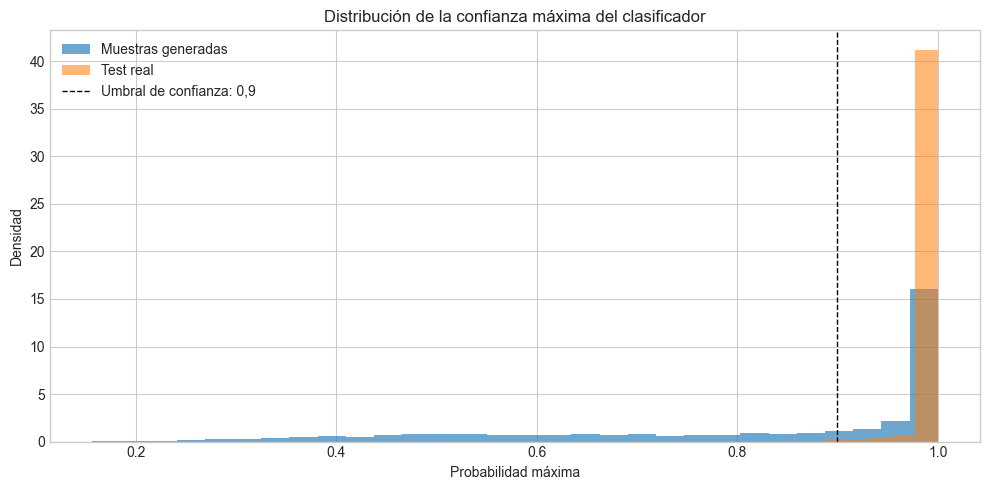

In [11]:
caracteristicas_generadas_metricas = []
probabilidades_generadas = []
confianzas_generadas = []
evaluator.eval()
with torch.inference_mode():
    for inicio in range(0, N_EVAL, EVAL_BATCH_SIZE):
        lote = imagenes_generadas_metricas[
            inicio:inicio + EVAL_BATCH_SIZE].to(device)
        caracteristicas_generadas_metricas.append(
            evaluator.features(lote).cpu().numpy())
        probabilidades = evaluator.probs(lote).cpu().numpy()
        probabilidades_generadas.append(probabilidades)
        confianzas_generadas.append(probabilidades.max(axis=1))

caracteristicas_generadas_metricas = np.concatenate(
    caracteristicas_generadas_metricas)
probabilidades_generadas = np.concatenate(probabilidades_generadas)
confianzas_generadas = np.concatenate(confianzas_generadas)
mu_generado, cov_generado = stats(caracteristicas_generadas_metricas)
fid_mnist_generado = frechet_distance(mu_train, cov_train, mu_generado, cov_generado)
is_clasificador_generado, is_clasificador_generado_std = classifier_is(
    probabilidades_generadas)
is_clasificador_real, is_clasificador_real_std = classifier_is(probabilidades_test)

clases_generadas = probabilidades_generadas.argmax(axis=1)
proporcion_clases_generadas = np.bincount(
    clases_generadas, minlength=10) / len(clases_generadas)
proporcion_clases_reales = np.bincount(
    etiquetas_test, minlength=10) / len(etiquetas_test)
entropia_normalizada_generada = -np.sum(
    proporcion_clases_generadas
    * np.log(np.clip(proporcion_clases_generadas, 1e-16, 1.0))
) / np.log(10)
entropia_normalizada_real = -np.sum(
    proporcion_clases_reales
    * np.log(np.clip(proporcion_clases_reales, 1e-16, 1.0))
) / np.log(10)

def resumen_confianza(confianzas):
    return {
        'media': float(np.mean(confianzas)),
        'desviacion': float(np.std(confianzas)),
        'mediana': float(np.median(confianzas)),
        'percentil_90': float(np.percentile(confianzas, 90)),
        'porcentaje_mayor_0_9': float(np.mean(confianzas > 0.9) * 100),
    }

resumen_confianza_generado = resumen_confianza(confianzas_generadas)
resumen_confianza_real = resumen_confianza(confianzas_test)

print(
    f'IS del clasificador — generado: {is_clasificador_generado:.4f} '
    f'± {is_clasificador_generado_std:.4f}; '
    f'test real: {is_clasificador_real:.4f} ± {is_clasificador_real_std:.4f}'
)
print(
    f'FID-MNIST — generado frente a entrenamiento real: '
    f'{fid_mnist_generado:.4f}; referencia test real: {fid_mnist_referencia:.4f}'
)
print('Proporción de clases generadas: '
      + np.array2string(proporcion_clases_generadas, precision=4))
print(
    f'Proporción de clase máxima/mínima: '
    f'{proporcion_clases_generadas.max():.4%} / '
    f'{proporcion_clases_generadas.min():.4%}'
)
print(
    f'Entropía normalizada de clases — generado: '
    f'{entropia_normalizada_generada:.4f}; real: {entropia_normalizada_real:.4f}'
)
print(f'Confianza máxima — generado: {resumen_confianza_generado}')
print(f'Confianza máxima — test real: {resumen_confianza_real}')

fig, ax = plt.subplots(figsize=(10, 5))
posiciones = np.arange(10)
ancho = 0.38
ax.bar(posiciones - ancho / 2, proporcion_clases_generadas, ancho,
       label='Muestras generadas')
ax.bar(posiciones + ancho / 2, proporcion_clases_reales, ancho,
       label='Test real')
ax.axhline(0.1, color='black', linestyle='--', linewidth=1,
           label='Distribución uniforme: 10 %')
ax.set_title('Distribución de clases predichas')
ax.set_xlabel('Dígito predicho')
ax.set_ylabel('Proporción')
ax.set_xticks(posiciones)
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(confianzas_generadas, bins=30, alpha=0.65, density=True,
        label='Muestras generadas')
ax.hist(confianzas_test, bins=30, alpha=0.55, density=True,
        label='Test real')
ax.axvline(0.9, color='black', linestyle='--', linewidth=1,
           label='Umbral de confianza: 0,9')
ax.set_title('Distribución de la confianza máxima del clasificador')
ax.set_xlabel('Probabilidad máxima')
ax.set_ylabel('Densidad')
ax.legend()
fig.tight_layout()
plt.show()

### 8.3. Resumen e interpretación

Las métricas de Inception son referencias relativas porque sus representaciones se aprendieron en ImageNet, un dominio distinto de MNIST. El FID depende del tamaño de la muestra; aquí se comparan las muestras generadas con el mismo número de imágenes reales de entrenamiento, pero se omite el FID real frente a real para reducir el tiempo de cómputo. El clasificador específico de dígitos añade una medida de similitud en el dominio, mientras que el histograma y la entropía ayudan a detectar clases omitidas o sobreproducidas.

In [12]:
filas_metricas = [
    {
        'Métrica': 'Inception Score (ImageNet)',
        'Generado': f'{is_generado.item():.4f} ± {is_generado_std.item():.4f}',
        'Referencia real': 'No calculada para IS',
        'Mejor si': '↑',
    },
    {
        'Métrica': 'FID (ImageNet)',
        'Generado': f'{fid_generado.item():.4f}',
        'Referencia real': '5 000 imágenes de entrenamiento',
        'Mejor si': '↓',
    },
    {
        'Métrica': 'Inception Score del clasificador',
        'Generado': f'{is_clasificador_generado:.4f} ± {is_clasificador_generado_std:.4f}',
        'Referencia real': f'{is_clasificador_real:.4f} ± {is_clasificador_real_std:.4f}',
        'Mejor si': '↑',
    },
    {
        'Métrica': 'FID-MNIST',
        'Generado': f'{fid_mnist_generado:.4f}',
        'Referencia real': f'{fid_mnist_referencia:.4f}',
        'Mejor si': '↓',
    },
    {
        'Métrica': 'Entropía normalizada de clases',
        'Generado': f'{entropia_normalizada_generada:.4f}',
        'Referencia real': f'{entropia_normalizada_real:.4f}',
        'Mejor si': '↑ (cerca de 1)',
    },
]

for digito in range(10):
    filas_metricas.append({
        'Métrica': f'Proporción de la clase {digito}',
        'Generado': f'{proporcion_clases_generadas[digito]:.2%}',
        'Referencia real': f'{proporcion_clases_reales[digito]:.2%}',
        'Mejor si': '≈ referencia',
    })

for estadistico in ('media', 'desviacion', 'mediana', 'percentil_90',
                   'porcentaje_mayor_0_9'):
    filas_metricas.append({
        'Métrica': f'Confianza máxima — {estadistico}',
        'Generado': f'{resumen_confianza_generado[estadistico]:.4f}',
        'Referencia real': f'{resumen_confianza_real[estadistico]:.4f}',
        'Mejor si': '≈ referencia',
    })

tabla_metricas = pd.DataFrame(filas_metricas)
print(f'Tiempo total de la sección de métricas: '
      f'{time.perf_counter() - inicio_metricas:.1f} s')
tabla_metricas

Tiempo total de la sección de métricas: 162.2 s


,Métrica,Generado,Referencia real,Mejor si
0,Inception Score (ImageNet),2.0014 ± 0.0317,No calculada para IS,↑
1,FID (ImageNet),183.0416,5 000 imágenes de entrenamiento,↓
2,Inception Score del clasificador,4.0692 ± 0.1024,9.5997 ± 0.0541,↑
3,FID-MNIST,655.4525,3.2296,↓
4,Entropía normalizada de clases,0.8191,0.9993,↑ (cerca de 1)
5,Proporción de la clase 0,1.96%,10.02%,≈ referencia
6,Proporción de la clase 1,40.76%,10.82%,≈ referencia
7,Proporción de la clase 2,7.58%,10.44%,≈ referencia
8,Proporción de la clase 3,10.54%,10.04%,≈ referencia
9,Proporción de la clase 4,8.90%,9.82%,≈ referencia


## 9. Conclusiones

### Evolución de los errores

- **No hay convergencia al equilibrio teórico.** En el óptimo del juego ($D = 0{,}5$ para todo) ambas pérdidas valdrían $\ln 2 \approx 0{,}693$. Aquí el discriminador domina durante todo el entrenamiento: su pérdida media por época se mueve entre 0,04 y 0,39, siempre por debajo de $\ln 2$, mientras que la del generador está entre 2,7 y 7,5. En la última época, $D(x) \approx 0{,}85$ y $D(G(z)) \approx 0{,}16$: el discriminador sigue separando bien lo real de lo generado.
- **Las curvas no son monótonas, como cabe esperar en un problema minimax.** Hay una fase inicial inestable (épocas 1–6), un pico de la pérdida del generador en torno a las épocas 10–12 (máximo de 7,46 en la época 12, con $D(G(z)) \approx 0{,}03$–$0{,}04$) y, a partir de la época 15, una tendencia lenta en la que la pérdida del discriminador sube (0,12 → 0,26) y la del generador baja (4,8 → 3,2). $D(G(z))$ pasa de 0,07 a 0,16: el generador va reduciendo poco a poco la ventaja del discriminador, aunque sigue lejos del equilibrio.
- **Las pérdidas no miden la calidad de las muestras.** La época 5 tiene la pérdida del generador más baja de todo el entrenamiento (2,66) y la mayor $D(G(z))$ (0,24). Aun así, su FID-MNIST (1572) es peor que el de la época 1, y en la figura de progresión todas las entradas latentes producen la misma mancha borrosa: el generador había colapsado en un único patrón que engañaba temporalmente a un discriminador todavía débil. En cambio, entre las épocas 10 y 25 el FID-MNIST baja de 1367 a 824 mientras la pérdida del generador sigue entre 4,7 y 7,5. Para seguir el progreso de una GAN hace falta una métrica de calidad externa (FID) y la inspección visual, no solo las pérdidas.

### Métricas del modelo final (50 épocas)

| Métrica | Generado | Referencia real | Lectura |
|:--|--:|--:|:--|
| FID-MNIST (clasificador propio) | 655,5 | 3,2 (test frente a entrenamiento) | Unas 200 veces la referencia: las muestras están aún lejos de la distribución real |
| Inception Score del clasificador | 4,07 ± 0,10 | 9,60 ± 0,05 (máx. 10) | Muestras menos nítidas y menos variadas que los dígitos reales |
| Entropía normalizada de clases | 0,82 | 0,999 | Diversidad de clases incompleta |
| Muestras con confianza > 0,9 | 56,9 % | 97,1 % | Muchas muestras son dígitos ambiguos o mal formados |
| FID (Inception, ImageNet) | 183,0 | no calculada | Solo sirve para comparar entre modelos |
| Inception Score (Inception, ImageNet) | 2,00 ± 0,03 | no calculada | Ídem |

- **Colapso de modos parcial.** El clasificador asigna el 40,8 % de las muestras generadas a la clase «1», frente a alrededor del 11 % en los datos reales, y apenas un 2,0 % al «0» y un 2,2 % al «8». El generador ha encontrado en el «1» (un trazo simple, fácil de imitar con un perceptrón multicapa) una forma barata de engañar al discriminador. Se ve también en la cuadrícula de muestras finales.
- **El FID-MNIST seguía mejorando al terminar** (mínimo de 597 en la época 48, 657 en la 50). Las oscilaciones de las últimas épocas indican ruido entre épocas, pero la tendencia es descendente: con más épocas el modelo probablemente mejoraría algo.
- **Las métricas de Inception son poco informativas aquí.** InceptionV3 se entrenó con fotografías de ImageNet en color, y un dígito gris de 28×28 reescalado a 299×299 queda fuera de su dominio. El IS de ImageNet mide cuántas clases *de ImageNet* reconoce, no si los dígitos son buenos. Sin la referencia real frente a real (omitida para ahorrar tiempo), los valores absolutos de 2,00 y 183,0 solo sirven para comparar esta GAN con otras evaluadas igual, con el mismo $N = 5000$. Las métricas basadas en un clasificador de MNIST (98,83 % de exactitud en test) sí tienen referencia real y permiten diagnosticar calidad, diversidad y colapso.

### Posibles mejoras

- Usar una arquitectura convolucional (DCGAN) en lugar de capas densas, que aprovecha la estructura espacial de las imágenes.
- Equilibrar el juego: Adam con $\beta_1 = 0{,}5$ (recomendado para GAN), *label smoothing* en las etiquetas reales (p. ej., 0,9) o *dropout* en el discriminador para que no domine tanto.
- Atacar el colapso de modos con *minibatch discrimination*, una GAN condicional (que fija la clase a generar) o una WGAN-GP, cuya pérdida además se correlaciona mejor con la calidad.
- Entrenar más épocas y guardar el generador con mejor FID-MNIST en lugar del de la última época.